# Tutorial 06: Batch Size Effect, Optimizers, Batch Normalization, Tuning

Assistant: [Alp Eren SARI](mailto:alp.sari@inf.unibe.ch)

## Batch Size

*    Larger batch size => better gradient estimation, lower noise.  

*    Small batch size => faster convergence with noisy gradient estimations, might behave like a regularization

Which batch size to use? Depends on your application. A good initial guess could be 32.
More information on [this link](https://medium.com/mini-distill/effect-of-batch-size-on-training-dynamics-21c14f7a716e)

# Cats vs dogs - different optimizers
We are using cats vs. dogs dataset used in Tutorial 01, 03 and 05. You may download it from [here](https://www.floydhub.com/swaroopgrs/datasets/dogscats) and extract it to your working folder. Alternatively, you can just run the cell below to download and extract it. If you are not running the notebook on Google Colab, make sure that you have gdown by using the command `pip install gdown`. If you are on Windows, the cell won't work. You need to download and extraact the data from the link. 

In [ ]:
!gdown --id 1sKjxoH-MQl3CBVEm6C0EHwV3rqtXOqWq
!mkdir dogscats
!tar -C dogscats/ -xf swaroopgrs-datasets-dogscats-1.tar

Downloading...
From: https://drive.google.com/uc?id=1sKjxoH-MQl3CBVEm6C0EHwV3rqtXOqWq
To: /content/swaroopgrs-datasets-dogscats-1.tar
887MB [00:10, 82.8MB/s]


In [54]:
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("We are using {}".format(device))

We are using cuda


In [55]:
from torchvision.datasets import ImageFolder
from torchvision.transforms import Resize, ToTensor, Normalize, Compose

target_size = (32, 32)

transforms = Compose([Resize(target_size), # Resizes image
                    ToTensor(),           # Converts to Tensor, scales to [0, 1] float (from [0, 255] int)
                    Normalize(mean=(0.5, 0.5, 0.5,), std=(0.5, 0.5, 0.5)), # scales to [-1.0, 1.0]
                    ])

# Load train data
root_dir = 'dogscats/train'
train_dataset_ = ImageFolder(root_dir, transform=transforms)

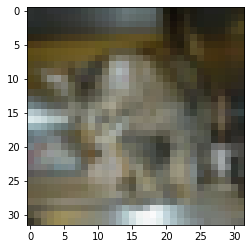

In [57]:
%matplotlib inline
import matplotlib.pyplot as plt
idx = np.random.randint(0, high=len(train_dataset_))
plt.imshow(train_dataset_[idx][0].permute(1,2,0)*0.5 + 0.5)

In [ ]:
from tqdm import tqdm

class RAMDatasetWrapper(torch.utils.data.Dataset):
    def __init__(self, dataset, transform=None):
        data = []
        for sample in tqdm(dataset):
            data.append(sample)
        self.n = len(dataset)
        self.data = data
        self.transform = transform
        
    def __getitem__(self, ind):
        if self.transform is not None:
            return self.transform(self.data[ind][0]), self.data[ind][1]
        else:
            return self.data[ind]
    
    def set_tranform(self, transform):
        self.transform = transform
    
    def __len__(self):
        return self.n

In [ ]:
train_dataset = RAMDatasetWrapper(train_dataset_)
# Load validation data
val_root_dir = 'dogscats/valid'
val_dataset_ = ImageFolder(val_root_dir, transform=transforms)
val_dataset = RAMDatasetWrapper(val_dataset_)

100%|██████████| 2000/2000 [00:06<00:00, 330.49it/s]


In [ ]:
def get_dataloaders(train_dataset, val_dataset, batch_size=32):
    train_dataloader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2)
    val_dataloader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=2)

    return train_dataloader, val_dataloader

In [ ]:
class MLPModel(nn.Module):
    
    def __init__(self, input_dim, hidden_dim):
        super(MLPModel, self).__init__()
        self.layers = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 2)
        )
    
    def forward(self, input):
        input = input.view(input.size(0), -1)
        return self.layers(input)

In [ ]:
import numpy as np

def train_epoch(model, train_dataloader, optimizer, loss_fn):
    losses = []
    correct_predictions = 0
    # Iterate mini batches over training dataset
    for images, labels in tqdm(train_dataloader):
        images = images.to(device)
        labels = labels.to(device)
        # Run predictions
        output = model(images)
        # Set gradients to zero
        optimizer.zero_grad()
        # Compute loss
        loss = loss_fn(output, labels)
        # Backpropagate (compute gradients)
        loss.backward()
        # Make an optimization step (update parameters)
        optimizer.step()
        # Log metrics
        losses.append(loss.item())
        predicted_labels = output.argmax(dim=1)
        correct_predictions += (predicted_labels == labels).sum().item()
    accuracy = 100.0 * correct_predictions / len(train_dataloader.dataset)
    # Return loss values for each iteration and accuracy
    mean_loss = np.array(losses).mean()
    return mean_loss, accuracy

def evaluate(model, dataloader, loss_fn):
    losses = []
    correct_predictions = 0
    with torch.no_grad():
        for images, labels in dataloader:
            images = images.to(device)
            labels = labels.to(device)
            # Run predictions
            output = model(images)
            # Compute loss
            loss = loss_fn(output, labels)
            # Save metrics
            predicted_labels = output.argmax(dim=1)
            correct_predictions += (predicted_labels == labels).sum().item()
            losses.append(loss.item())
    mean_loss = np.array(losses).mean()
    accuracy = 100.0 * correct_predictions / len(dataloader.dataset)
    # Return mean loss and accuracy
    return mean_loss, accuracy

def train(model, train_dataloader, val_dataloader, optimizer, n_epochs, loss_function):
    # We will monitor loss functions as the training progresses
    train_losses = []
    val_losses = []
    train_accuracies = []
    val_accuracies = []

    for epoch in range(n_epochs):
        model.train()
        train_loss, train_accuracy = train_epoch(model, train_dataloader, optimizer, loss_fn)
        model.eval()
        val_loss, val_accuracy = evaluate(model, val_dataloader, loss_fn)
        train_losses.append(train_loss)
        val_losses.append(val_loss)
        train_accuracies.append(train_accuracy)
        val_accuracies.append(val_accuracy)
        print('Epoch {}/{}: train_loss: {:.4f}, train_accuracy: {:.4f}, val_loss: {:.4f}, val_accuracy: {:.4f}'.format(epoch+1, n_epochs,
                                                                                                      train_losses[-1],
                                                                                                      train_accuracies[-1],
                                                                                                      val_losses[-1],
                                                                                                      val_accuracies[-1]))
    return train_losses, train_accuracies, val_losses, val_accuracies

In [ ]:
training_curves_batch_size = {}

In [ ]:
model = MLPModel(32*32*3, 128)
model = model.to(device)
learning_rate = 0.01
## STANDARD SGD
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)
n_epochs = 25
loss_fn = nn.CrossEntropyLoss()

# set batch size to 32
batch_size = 32
train_dataloader, val_dataloader =  get_dataloaders(train_dataset, val_dataset, batch_size=batch_size)

curves = train(model, train_dataloader, val_dataloader, optimizer, n_epochs, loss_fn)
training_curves_batch_size[f"{batch_size}"] = curves

  0%|          | 0/719 [00:00<?, ?it/s]

Epoch 1/25: train_loss: 0.6883, train_accuracy: 55.3043, val_loss: 0.6812, val_accuracy: 57.6000


  0%|          | 0/719 [00:00<?, ?it/s]

Epoch 2/25: train_loss: 0.6664, train_accuracy: 61.4130, val_loss: 0.6567, val_accuracy: 59.8500


  0%|          | 0/719 [00:00<?, ?it/s]

...

Epoch 23/25: train_loss: 0.3530, train_accuracy: 84.6783, val_loss: 0.7732, val_accuracy: 65.8500


  0%|          | 0/719 [00:00<?, ?it/s]

Epoch 24/25: train_loss: 0.3363, train_accuracy: 85.1609, val_loss: 0.7758, val_accuracy: 65.3000


100%|██████████| 719/719 [00:02<00:00, 306.73it/s]


Epoch 25/25: train_loss: 0.3212, train_accuracy: 86.1609, val_loss: 0.8018, val_accuracy: 66.4000


In [ ]:
model = MLPModel(32*32*3, 128)
model = model.to(device)
learning_rate = 0.01
## STANDARD SGD
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)
n_epochs = 25
loss_fn = nn.CrossEntropyLoss()

# set batch size to 128
batch_size = 128
train_dataloader, val_dataloader =  get_dataloaders(train_dataset, val_dataset, batch_size=batch_size)

# train
curves = train(model, train_dataloader, val_dataloader, optimizer, n_epochs, loss_fn)
training_curves_batch_size[f"{batch_size}"] = curves

  0%|          | 0/180 [00:00<?, ?it/s]

Epoch 1/25: train_loss: 0.6923, train_accuracy: 53.5348, val_loss: 0.6910, val_accuracy: 57.2000


  0%|          | 0/180 [00:00<?, ?it/s]

Epoch 2/25: train_loss: 0.6901, train_accuracy: 57.5217, val_loss: 0.6889, val_accuracy: 59.0500


  0%|          | 0/180 [00:00<?, ?it/s]

...

Epoch 23/25: train_loss: 0.5527, train_accuracy: 72.0261, val_loss: 0.6027, val_accuracy: 66.2500


  0%|          | 0/180 [00:00<?, ?it/s]

Epoch 24/25: train_loss: 0.5451, train_accuracy: 72.6174, val_loss: 0.6051, val_accuracy: 67.1000


100%|██████████| 180/180 [00:00<00:00, 228.89it/s]


Epoch 25/25: train_loss: 0.5384, train_accuracy: 72.8478, val_loss: 0.6054, val_accuracy: 67.2500


In [ ]:
model = MLPModel(32*32*3, 128)
model = model.to(device)
learning_rate = 0.01
## STANDARD SGD
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)
n_epochs = 25
loss_fn = nn.CrossEntropyLoss()

# set batch size to 256
batch_size = 256
train_dataloader, val_dataloader =  get_dataloaders(train_dataset, val_dataset, batch_size=batch_size)

# train
curves = train(model, train_dataloader, val_dataloader, optimizer, n_epochs, loss_fn)
training_curves_batch_size[f"{batch_size}"] = curves

  0%|          | 0/90 [00:00<?, ?it/s]

Epoch 1/25: train_loss: 0.6936, train_accuracy: 50.0043, val_loss: 0.6934, val_accuracy: 50.0500


  0%|          | 0/90 [00:00<?, ?it/s]

Epoch 2/25: train_loss: 0.6918, train_accuracy: 50.4478, val_loss: 0.6917, val_accuracy: 50.7500


  0%|          | 0/90 [00:00<?, ?it/s]

...

Epoch 23/25: train_loss: 0.6180, train_accuracy: 65.9913, val_loss: 0.6334, val_accuracy: 62.9500


  0%|          | 0/90 [00:00<?, ?it/s]

Epoch 24/25: train_loss: 0.6146, train_accuracy: 66.3652, val_loss: 0.6329, val_accuracy: 64.3000


100%|██████████| 90/90 [00:00<00:00, 158.21it/s]


Epoch 25/25: train_loss: 0.6111, train_accuracy: 66.8087, val_loss: 0.6298, val_accuracy: 64.4000


Let's try to use larger learning rate with larger batch size

In [ ]:
model = MLPModel(32*32*3, 128)
model = model.to(device)
learning_rate = 1.0
## STANDARD SGD
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)
n_epochs = 25
loss_fn = nn.CrossEntropyLoss()

# set batch size to 256
batch_size = 256
train_dataloader, val_dataloader =  get_dataloaders(train_dataset, val_dataset, batch_size=batch_size)

# train
curves = train(model, train_dataloader, val_dataloader, optimizer, n_epochs, loss_fn)
training_curves_batch_size[f"{batch_size}_learning_rate_1"] = curves

  0%|          | 0/90 [00:00<?, ?it/s]

Epoch 1/25: train_loss: 0.6632, train_accuracy: 59.6522, val_loss: 0.7118, val_accuracy: 52.0500


  0%|          | 0/90 [00:00<?, ?it/s]

Epoch 2/25: train_loss: 0.6418, train_accuracy: 62.6957, val_loss: 0.6535, val_accuracy: 62.2500


  0%|          | 0/90 [00:00<?, ?it/s]

...

Epoch 23/25: train_loss: 0.3347, train_accuracy: 84.6522, val_loss: 0.8284, val_accuracy: 66.1500


  0%|          | 0/90 [00:00<?, ?it/s]

Epoch 24/25: train_loss: 0.3230, train_accuracy: 85.0957, val_loss: 0.8967, val_accuracy: 65.0500


100%|██████████| 90/90 [00:00<00:00, 155.94it/s]


Epoch 25/25: train_loss: 0.3067, train_accuracy: 86.3304, val_loss: 0.9351, val_accuracy: 65.5000


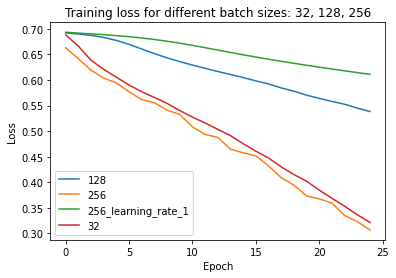

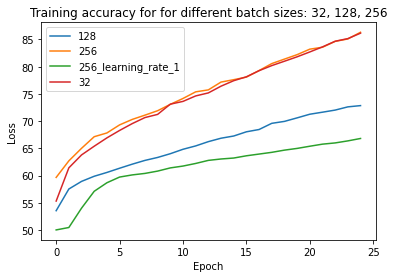

In [ ]:
keys = []
for k, v in sorted(training_curves_batch_size.items()):
    plt.plot(np.arange(len(v[0])), v[0])
    keys.append(k)
plt.title('Training loss for different batch sizes: 32, 128, 256')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(keys);

plt.figure()
keys = []
for k, v in sorted(training_curves_batch_size.items()):
    plt.plot(np.arange(len(v[1])), v[1])
    keys.append(k)
plt.title('Training accuracy for for different batch sizes: 32, 128, 256')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(keys);

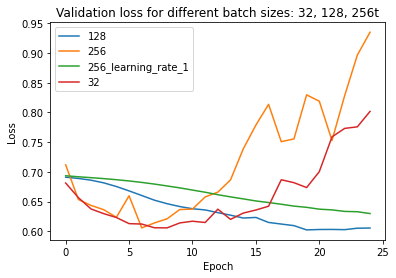

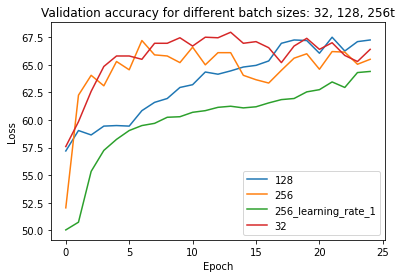

In [ ]:
keys = []
for k, v in sorted(training_curves_batch_size.items()):
    plt.plot(np.arange(len(v[2])), v[2])
    keys.append(k)
plt.title('Validation loss for different batch sizes: 32, 128, 256t')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(keys);

plt.figure()
keys = []
for k, v in sorted(training_curves_batch_size.items()):
    plt.plot(np.arange(len(v[3])), v[3])
    keys.append(k)
plt.title('Validation accuracy for different batch sizes: 32, 128, 256t')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(keys);

## Optimizers

**Recommended blogpost: http://ruder.io/optimizing-gradient-descent/index.html**  

So far we've used mini-batch stochastic gradient descent from `torch.optim.SGD` to minimize a loss funciton $J$.  
That's what happens when we run `optimizer.step()`:    
$\theta \gets \theta - \alpha * \nabla_\theta J(\theta; x, y)$  
Where $(x, y)$ - datapoints with corresponding labels/true values. $\theta$ - parameters we wish to optimize

However, it doesn't always provide the best direction for finding minimum

<img src="https://drive.google.com/uc?export=view&id=1J6OvmwHgRTlLUFQlae8PyvWErJM7Qznp" width="500" />

^ The gradient is highest in vertical direction, but we should move in horizontal direction

Other methods can find minimum faster:

<img src="https://drive.google.com/uc?export=view&id=1muZybYPt1oxq8DCDn-c5Czm3IzrHHS-X" width="500" />

And are more robust to non-convex functions, e.g. saddle points  

<img src="https://drive.google.com/uc?export=view&id=19lJ2A8xjYGXORkBIkRWnrA6QECcClJFt" width="500" />



## SGD with Momentum

\begin{align}
\begin{split}
v_t = \gamma v_{t-1} + \eta \nabla_\theta J( \theta) \\
\theta = \theta - v_t
\end{split}
\end{align}

## Nesterov accelerated gradient

\begin{align}
\begin{split}
v_t = \gamma v_{t-1} + \eta \nabla_\theta J( \theta - \gamma v_{t-1} ) \\
\theta = \theta - v_t
\end{split}
\end{align}

## Adagrad

\begin{align}
\begin{split}
g_{t, i} = \nabla_\theta J( \theta_{t, i} )
\end{split}
\end{align}

<!-- <p>The SGD update for every parameter \(\theta_i\) at each time step \(t\) then becomes:</p>
<p>\(\theta_{t+1, i} = \theta_{t, i} - \eta \cdot g_{t, i}\).</p>

<p>In its update rule, Adagrad modifies the general learning rate \(\eta\) at each time step \(t\) for every parameter \(\theta_i\) based on the past gradients that have been computed for \(\theta_i\): -->

<!-- \begin{align}
\begin{split}
\theta_{t+1, i} = \theta_{t, i} - \dfrac{\eta}{\sqrt{G_{t, ii} + \epsilon}} \cdot g_{t, i}
\end{split} 
\end{align}

<p>\(G_{t} \in \mathbb{R}^{d \times d} \) here is a diagonal matrix where each diagonal element \(i, i\) is the sum of the squares of the gradients w.r.t. \(\theta_i\) up to time step \(t\) <sup class="footnote-ref"><a href="index.html#fn12" id="fnref12">[12]</a></sup>, while \(\epsilon\) is a smoothing term that avoids division by zero (usually on the order of \(1e-8\)). Interestingly, without the square root operation, the algorithm performs much worse.</p>
<p>As \(G_{t}\) contains the sum of the squares of the past gradients w.r.t. to all parameters \(\theta\) along its diagonal, we can now vectorize our implementation by performing a matrix-vector product \(\odot\) between \(G_{t}\) and \(g_{t}\):</p> -->

\begin{align}
\begin{split}
\theta_{t+1} = \theta_{t} - \dfrac{\eta}{\sqrt{G_{t} + \epsilon}} \odot g_{t}
\end{split} 
\end{align}

## RMSProp

\begin{align}
\begin{split}
E[g^2]_t = 0.9 E[g^2]_{t-1} + 0.1 g^2_t \\ 
\theta_{t+1} = \theta_{t} - \dfrac{\eta}{\sqrt{E[g^2]_t + \epsilon}} g_{t}
\end{split} 
\end{align}

## ADAM

\begin{align}
\begin{split}
m_t = \beta_1 m_{t-1} + (1 - \beta_1) g_t \\
v_t = \beta_2 v_{t-1} + (1 - \beta_2) g_t^2 \\
\hat{m}_t = \dfrac{m_t}{1 - \beta^t_1} \\
\hat{v}_t = \dfrac{v_t}{1 - \beta^t_2} \\
\theta_{t+1} = \theta_{t} - \dfrac{\eta}{\sqrt{\hat{v}_t} + \epsilon} \hat{m}_t
\end{split}
\end{align}



# Train with different optimizers
https://pytorch.org/docs/stable/optim.html#algorithms

In [ ]:
training_curves = {}

## SGD
https://pytorch.org/docs/stable/optim.html#torch.optim.SGD

In [ ]:
model = MLPModel(32*32*3, 128)
model = model.to(device)
learning_rate = 0.001
## STANDARD SGD
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)
n_epochs = 25
loss_fn = nn.CrossEntropyLoss()

# set batch size to 32
batch_size = 32
train_dataloader, val_dataloader =  get_dataloaders(train_dataset, val_dataset, batch_size=batch_size)

curves = train(model, train_dataloader, val_dataloader, optimizer, n_epochs, loss_fn)
training_curves['sgd'] = curves

  0%|          | 0/719 [00:00<?, ?it/s]

Epoch 1/25: train_loss: 0.6928, train_accuracy: 51.6391, val_loss: 0.6920, val_accuracy: 53.2500


  0%|          | 0/719 [00:00<?, ?it/s]

Epoch 2/25: train_loss: 0.6918, train_accuracy: 54.4609, val_loss: 0.6911, val_accuracy: 55.7500


  0%|          | 0/719 [00:00<?, ?it/s]

...

Epoch 23/25: train_loss: 0.6419, train_accuracy: 63.6478, val_loss: 0.6469, val_accuracy: 62.1000


  0%|          | 0/719 [00:00<?, ?it/s]

Epoch 24/25: train_loss: 0.6387, train_accuracy: 63.9957, val_loss: 0.6449, val_accuracy: 62.1000


100%|██████████| 719/719 [00:02<00:00, 295.20it/s]


Epoch 25/25: train_loss: 0.6357, train_accuracy: 64.1870, val_loss: 0.6430, val_accuracy: 62.1500


## SGD with momentum
https://pytorch.org/docs/stable/optim.html#torch.optim.SGD

In [ ]:
# Reinitialize model 
model = MLPModel(32*32*3, 128)
model = model.to(device)
learning_rate = 0.001
## SGD WITH MOMENTUM
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate, momentum=0.9)
n_epochs = 25
loss_fn = nn.CrossEntropyLoss()

curves = train(model, train_dataloader, val_dataloader, optimizer, n_epochs, loss_fn)
training_curves['sgd_momentum'] = curves

  0%|          | 0/719 [00:00<?, ?it/s]

Epoch 1/25: train_loss: 0.6859, train_accuracy: 56.7870, val_loss: 0.6755, val_accuracy: 59.8000


  0%|          | 0/719 [00:00<?, ?it/s]

Epoch 2/25: train_loss: 0.6625, train_accuracy: 61.2348, val_loss: 0.6504, val_accuracy: 61.5000


  0%|          | 0/719 [00:00<?, ?it/s]

...

Epoch 23/25: train_loss: 0.3423, train_accuracy: 85.1087, val_loss: 0.7175, val_accuracy: 67.4000


  0%|          | 0/719 [00:00<?, ?it/s]

Epoch 24/25: train_loss: 0.3330, train_accuracy: 85.1304, val_loss: 0.7251, val_accuracy: 66.7500


100%|██████████| 719/719 [00:02<00:00, 285.53it/s]


Epoch 25/25: train_loss: 0.3085, train_accuracy: 86.8000, val_loss: 0.7645, val_accuracy: 66.8000


## SGD with Nesterov Momentum
https://pytorch.org/docs/stable/optim.html#torch.optim.SGD

In [ ]:
# Reinitialize model 
model = MLPModel(32*32*3, 128)
model = model.to(device)
learning_rate = 0.001
## SGD WITH NESTEROV MOMENTUM
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate, momentum=0.9, nesterov=True)
n_epochs = 25
loss_fn = nn.CrossEntropyLoss()

curves = train(model, train_dataloader, val_dataloader, optimizer, n_epochs, loss_fn)
training_curves['sgd_nesterov'] = curves

  0%|          | 0/719 [00:00<?, ?it/s]

Epoch 1/25: train_loss: 0.6892, train_accuracy: 55.1739, val_loss: 0.6822, val_accuracy: 59.5500


  0%|          | 0/719 [00:00<?, ?it/s]

Epoch 2/25: train_loss: 0.6695, train_accuracy: 60.9217, val_loss: 0.6570, val_accuracy: 61.6500


  0%|          | 0/719 [00:00<?, ?it/s]

...

Epoch 23/25: train_loss: 0.3201, train_accuracy: 86.0043, val_loss: 0.7791, val_accuracy: 65.4500


  0%|          | 0/719 [00:00<?, ?it/s]

Epoch 24/25: train_loss: 0.2980, train_accuracy: 87.5261, val_loss: 0.7967, val_accuracy: 67.0500


100%|██████████| 719/719 [00:02<00:00, 277.88it/s]


Epoch 25/25: train_loss: 0.2867, train_accuracy: 87.9304, val_loss: 0.8168, val_accuracy: 65.8500


## Adagrad
https://pytorch.org/docs/stable/optim.html#torch.optim.Adagrad

In [ ]:
# Reinitialize model 
model = MLPModel(32*32*3, 128)
model = model.to(device)
learning_rate = 0.001
## ADAGRAD
optimizer = torch.optim.Adagrad(model.parameters(), lr=learning_rate)
n_epochs = 25
loss_fn = nn.CrossEntropyLoss()

curves = train(model, train_dataloader, val_dataloader, optimizer, n_epochs, loss_fn)
training_curves['adagrad'] = curves

  0%|          | 0/719 [00:00<?, ?it/s]

Epoch 1/25: train_loss: 0.6482, train_accuracy: 61.8435, val_loss: 0.6375, val_accuracy: 64.0000


  0%|          | 0/719 [00:00<?, ?it/s]

Epoch 2/25: train_loss: 0.6197, train_accuracy: 65.5087, val_loss: 0.6280, val_accuracy: 64.1000


  0%|          | 0/719 [00:00<?, ?it/s]

...

Epoch 23/25: train_loss: 0.4641, train_accuracy: 78.4478, val_loss: 0.6064, val_accuracy: 68.7000


  0%|          | 0/719 [00:00<?, ?it/s]

Epoch 24/25: train_loss: 0.4591, train_accuracy: 78.8696, val_loss: 0.6082, val_accuracy: 68.7500


100%|██████████| 719/719 [00:02<00:00, 276.95it/s]


Epoch 25/25: train_loss: 0.4537, train_accuracy: 79.1261, val_loss: 0.6038, val_accuracy: 68.8000


## RMSprop
https://pytorch.org/docs/stable/optim.html#torch.optim.RMSprop

In [ ]:
# Reinitialize model 
model = MLPModel(32*32*3, 128)
model = model.to(device)
learning_rate = 0.001 # doesn't work with 0.01
## RMSProp
optimizer = torch.optim.RMSprop(model.parameters(), lr=learning_rate)
n_epochs = 25
loss_fn = nn.CrossEntropyLoss()

curves = train(model, train_dataloader, val_dataloader, optimizer, n_epochs, loss_fn)
training_curves['rmsprop'] = curves

  0%|          | 0/719 [00:00<?, ?it/s]

Epoch 1/25: train_loss: 0.6578, train_accuracy: 60.9000, val_loss: 0.6364, val_accuracy: 63.4500


  0%|          | 0/719 [00:00<?, ?it/s]

Epoch 2/25: train_loss: 0.6177, train_accuracy: 65.6261, val_loss: 0.6319, val_accuracy: 64.7500


  0%|          | 0/719 [00:00<?, ?it/s]

...

Epoch 23/25: train_loss: 0.1809, train_accuracy: 92.5522, val_loss: 1.4905, val_accuracy: 64.9000


  0%|          | 0/719 [00:00<?, ?it/s]

Epoch 24/25: train_loss: 0.1708, train_accuracy: 92.7174, val_loss: 1.6125, val_accuracy: 65.2500


100%|██████████| 719/719 [00:02<00:00, 262.66it/s]


Epoch 25/25: train_loss: 0.1614, train_accuracy: 93.1478, val_loss: 1.8912, val_accuracy: 65.4500


## ADAM
https://pytorch.org/docs/stable/optim.html#torch.optim.Adam

In [ ]:
# Reinitialize model 
model = MLPModel(32*32*3, 128)
model = model.to(device)
learning_rate = 0.001 # 0.01 too big for this network
## ADAM // betas=(0.9, 0.999) - default parameters
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
n_epochs = 25
loss_fn = nn.CrossEntropyLoss()

curves = train(model, train_dataloader, val_dataloader, optimizer, n_epochs, loss_fn)
training_curves['adam'] = curves

  0%|          | 0/719 [00:00<?, ?it/s]

Epoch 1/25: train_loss: 0.6526, train_accuracy: 61.1609, val_loss: 0.6316, val_accuracy: 64.1500


  0%|          | 0/719 [00:00<?, ?it/s]

Epoch 2/25: train_loss: 0.6221, train_accuracy: 64.7870, val_loss: 0.6309, val_accuracy: 65.0500


  0%|          | 0/719 [00:00<?, ?it/s]

...

Epoch 23/25: train_loss: 0.1751, train_accuracy: 92.5261, val_loss: 1.4062, val_accuracy: 66.5000


  0%|          | 0/719 [00:00<?, ?it/s]

Epoch 24/25: train_loss: 0.1665, train_accuracy: 92.9435, val_loss: 1.5843, val_accuracy: 66.0500


100%|██████████| 719/719 [00:02<00:00, 253.27it/s]


Epoch 25/25: train_loss: 0.1574, train_accuracy: 93.4522, val_loss: 1.5982, val_accuracy: 65.4500


In [ ]:
%matplotlib inline
import matplotlib.pyplot as plt

## Training losses and accuracies

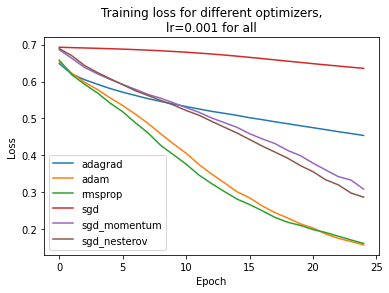

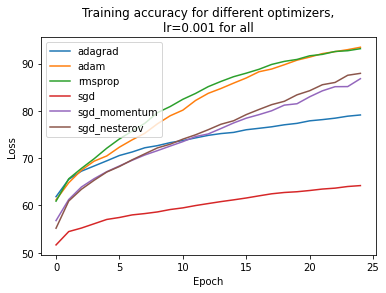

In [ ]:
keys = []
for k, v in sorted(training_curves.items()):
    plt.plot(np.arange(len(v[0])), v[0])
    keys.append(k)
plt.title('Training loss for different optimizers,\nlr=0.001 for all')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(keys);

plt.figure()
keys = []
for k, v in sorted(training_curves.items()):
    plt.plot(np.arange(len(v[1])), v[1])
    keys.append(k)
plt.title('Training accuracy for different optimizers,\nlr=0.001 for all')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(keys);

**Much faster training with momentum and adaptive optimizers!**

## Validation losses and accuracies

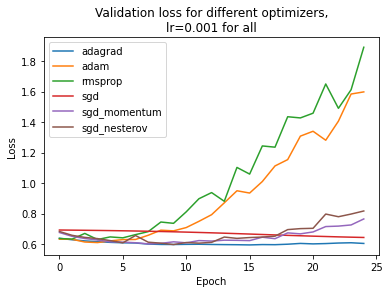

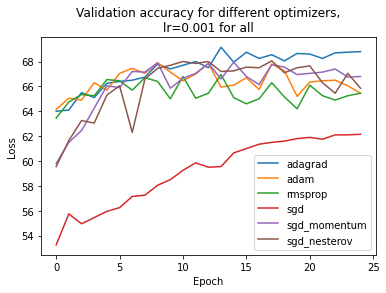

In [ ]:
keys = []
for k, v in sorted(training_curves.items()):
    plt.plot(np.arange(len(v[2])), v[2])
    keys.append(k)
plt.title('Validation loss for different optimizers,\nlr=0.001 for all')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(keys);

plt.figure()
keys = []
for k, v in sorted(training_curves.items()):
    plt.plot(np.arange(len(v[3])), v[3])
    keys.append(k)
plt.title('Validation accuracy for different optimizers,\nlr=0.001 for all')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(keys);

On validation set, we can observe **overfitting** much faster

# Which optimizer to use?
Depends on the problem but often **ADAM** is a good default option (http://ruder.io/optimizing-gradient-descent/index.html#whichoptimizertochoose)

# Learning rate schedules
Often it's good to start with relatively large learning rate when we start the training and are far from optimum, and lower it when we're getting closer -- make smaller steps to reach the minimum.

## Possible learning rate schedules
Also implemented in PyTorch: https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate

### Step
Reduce learning rate after a certain number of epochs

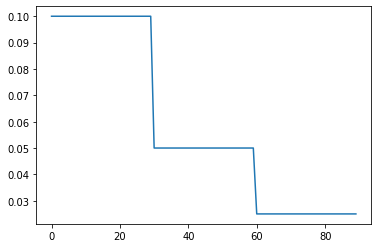

In [ ]:
lr = [0.1 for i in range(30)] + [0.05 for i in range(30)] + [0.025 for i in range(30)]
plt.plot(np.arange(90), lr)

### Exponential
Multiply by gamma < 1 after every epoch

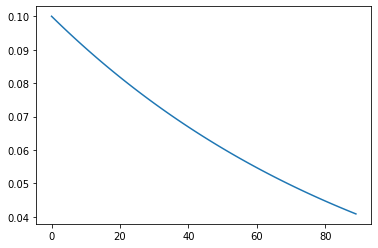

In [ ]:
gamma = 0.99
lr = [0.1 * gamma ** i for i in range(90)]
plt.plot(np.arange(90), lr)

### Cosine annealing
Starts decreasing slowly, than slowly reaches minimum

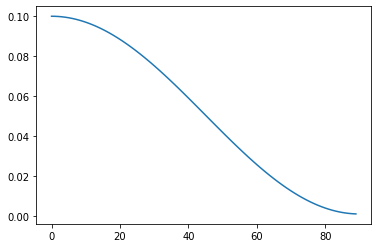

In [ ]:
import math

base_lr = 0.1
max_iterations = 90
min_lr = 0.001
lr = [min_lr + (base_lr - min_lr) *
                (1 + math.cos(math.pi * i / max_iterations)) / 2 for i in range(90)]
plt.plot(np.arange(90), lr)

### ReduceLR on plateau
Monitor loss/accuracy, reduce learning rate when it stops training

# Learning rate schedule examples

## Reduce every 10 epochs

In [ ]:
def train_scheduler(model, train_dataloader, val_dataloader, optimizer, n_epochs, loss_function, scheduler=None):
    # We will monitor loss functions as the training progresses
    train_losses = []
    val_losses = []
    train_accuracies = []
    val_accuracies = []
    learning_rates = []

    for epoch in range(n_epochs):
        model.train()
        train_loss, train_accuracy = train_epoch(model, train_dataloader, optimizer, loss_fn)
        model.eval()
        val_loss, val_accuracy = evaluate(model, val_dataloader, loss_fn)
        train_losses.append(train_loss)
        val_losses.append(val_loss)
        train_accuracies.append(train_accuracy)
        val_accuracies.append(val_accuracy)
        # We'll monitor learning rate -- just to show that it's decreasing
        learning_rates.append(optimizer.param_groups[0]['lr'])
        ########## Notify a scheduler that an epoch passed
        if scheduler:
            scheduler.step() # argument only needed for ReduceLROnPlateau
        print('Epoch {}/{}: train_loss: {:.4f}, train_accuracy: {:.4f}, val_loss: {:.4f}, val_accuracy: {:.4f}'.format(epoch+1, n_epochs,
                                                                                                      train_losses[-1],
                                                                                                      train_accuracies[-1],
                                                                                                      val_losses[-1],
                                                                                                      val_accuracies[-1]))
    return train_losses, train_accuracies, val_losses, val_accuracies, learning_rates

In [ ]:
# Reinitialize model 
model = MLPModel(32*32*3, 128)
model = model.to(device)
learning_rate = 0.01
## ADAM // betas=(0.9, 0.999) - default parameters
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate, momentum=0.9)
n_epochs = 25
loss_fn = nn.CrossEntropyLoss()

https://pytorch.org/docs/stable/optim.html#torch.optim.lr_scheduler.StepLR

In [ ]:
scheduler = torch.optim.lr_scheduler.StepLR(optimizer=optimizer, step_size=10, gamma=0.1) 

In [ ]:
curves_lr_scheduler = train_scheduler(model, train_dataloader, val_dataloader, optimizer, n_epochs, loss_fn, scheduler)

  0%|          | 0/719 [00:00<?, ?it/s]

Epoch 1/25: train_loss: 0.6547, train_accuracy: 60.8043, val_loss: 0.6334, val_accuracy: 65.1500


  0%|          | 0/719 [00:00<?, ?it/s]

Epoch 2/25: train_loss: 0.6175, train_accuracy: 65.2783, val_loss: 0.6179, val_accuracy: 64.2000


  0%|          | 0/719 [00:00<?, ?it/s]

...

Epoch 23/25: train_loss: 0.1473, train_accuracy: 94.6696, val_loss: 1.0630, val_accuracy: 67.0500


  0%|          | 0/719 [00:00<?, ?it/s]

Epoch 24/25: train_loss: 0.1444, train_accuracy: 94.8217, val_loss: 1.0733, val_accuracy: 67.1000


100%|██████████| 719/719 [00:02<00:00, 285.57it/s]


Epoch 25/25: train_loss: 0.1421, train_accuracy: 94.8870, val_loss: 1.0867, val_accuracy: 66.9500


In [ ]:
# Reinitialize model 
model = MLPModel(32*32*3, 128)
model = model.to(device)
learning_rate = 0.05
## ADAM // betas=(0.9, 0.999) - default parameters
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate, momentum=0.9)
n_epochs = 25
loss_fn = nn.CrossEntropyLoss()

In [ ]:
curves_constant_lr = train_scheduler(model, train_dataloader, val_dataloader, optimizer, n_epochs, loss_fn)

  0%|          | 0/719 [00:00<?, ?it/s]

Epoch 1/25: train_loss: 0.6608, train_accuracy: 59.9565, val_loss: 0.6544, val_accuracy: 60.9000


  0%|          | 0/719 [00:00<?, ?it/s]

Epoch 2/25: train_loss: 0.6333, train_accuracy: 63.8130, val_loss: 0.6338, val_accuracy: 63.5500


  0%|          | 0/719 [00:00<?, ?it/s]

...

Epoch 23/25: train_loss: 0.4712, train_accuracy: 77.2174, val_loss: 0.7628, val_accuracy: 64.8500


  0%|          | 0/719 [00:00<?, ?it/s]

Epoch 24/25: train_loss: 0.4743, train_accuracy: 76.3696, val_loss: 0.9306, val_accuracy: 64.7500


100%|██████████| 719/719 [00:02<00:00, 293.09it/s]


Epoch 25/25: train_loss: 0.4729, train_accuracy: 76.9217, val_loss: 0.7697, val_accuracy: 66.0000


Text(0.5, 1.0, 'Step learning rate schedule')

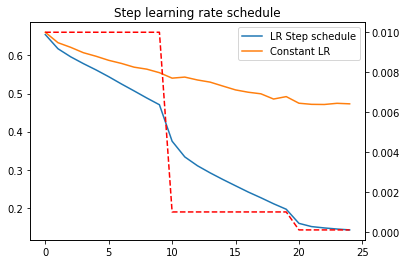

In [ ]:
fig, ax1 = plt.subplots()
x = np.arange(25)
ax1.plot(curves_lr_scheduler[0]) # training loss
ax1.plot(curves_constant_lr[0])
ax1.legend(['LR Step schedule', 'Constant LR'])
ax2 = ax1.twinx()
ax2.plot(curves_lr_scheduler[4], 'r--') #learning rates
plt.title('Step learning rate schedule')

**We can see faster training when we decreased learning rate**

## Batch Norm

Batch normalization is a method to standardise the inputs to each layer. Therefore, it makes faster and more stable training of neural networks possible. In pytorch, you can use batch normalization by adding `nn.BatchNorm1d()` or `nn.BatchNorm2d()` blocks to your model. Usually, it is used before the nonlinear activation function. For more tips about usign batch normalization visit [this link](https://machinelearningmastery.com/batch-normalization-for-training-of-deep-neural-networks/).


\begin{align}
\begin{split}
\hat{x}_{i}^{k} = \frac{x_{i}^{k} - \mu_{B}^{k}}{\sqrt{(\sigma_{B}^{k})^2 + \epsilon}} \\
y_i^k = \gamma_k \hat{x}_{i}^{k} + \beta^k
\end{split}
\end{align}

In [ ]:
class MLPModelBatchNorm(nn.Module):
    
    def __init__(self, input_dim, hidden_dim):
        super(MLPModelBatchNorm, self).__init__()
        self.layers = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 2)
        )
    
    def forward(self, input):
        input = input.view(input.size(0), -1)
        return self.layers(input)

In [ ]:
batcnorm_training_curves = {}
batcnorm_training_curves['sgd'] = training_curves['sgd']

In [ ]:
model = MLPModelBatchNorm(32*32*3, 128)
model = model.to(device)
learning_rate = 0.001
## STANDARD SGD
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)
n_epochs = 25
loss_fn = nn.CrossEntropyLoss()

curves = train(model, train_dataloader, val_dataloader, optimizer, n_epochs, loss_fn)
batcnorm_training_curves['sgd_batchnorm'] = curves

  0%|          | 0/719 [00:00<?, ?it/s]

Epoch 1/25: train_loss: 0.6653, train_accuracy: 59.3000, val_loss: 0.6386, val_accuracy: 62.3000


  0%|          | 0/719 [00:00<?, ?it/s]

Epoch 2/25: train_loss: 0.6264, train_accuracy: 64.2435, val_loss: 0.6315, val_accuracy: 63.4000


  0%|          | 0/719 [00:00<?, ?it/s]

...

Epoch 23/25: train_loss: 0.3737, train_accuracy: 83.5739, val_loss: 0.6601, val_accuracy: 67.3500


  0%|          | 0/719 [00:00<?, ?it/s]

Epoch 24/25: train_loss: 0.3581, train_accuracy: 84.5087, val_loss: 0.6991, val_accuracy: 66.6000


100%|██████████| 719/719 [00:02<00:00, 243.21it/s]


Epoch 25/25: train_loss: 0.3476, train_accuracy: 84.8913, val_loss: 0.6988, val_accuracy: 66.1500


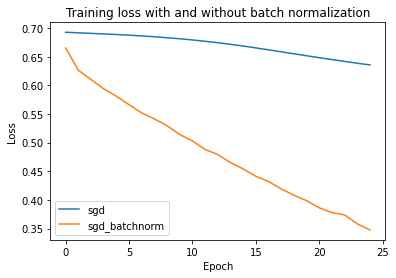

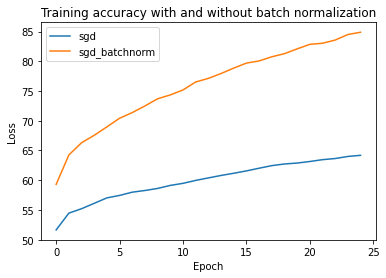

In [ ]:
keys = []
for k, v in sorted(batcnorm_training_curves.items()):
    plt.plot(np.arange(len(v[0])), v[0])
    keys.append(k)
plt.title('Training loss with and without batch normalization')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(keys);

plt.figure()
keys = []
for k, v in sorted(batcnorm_training_curves.items()):
    plt.plot(np.arange(len(v[1])), v[1])
    keys.append(k)
plt.title('Training accuracy with and without batch normalization')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(keys);

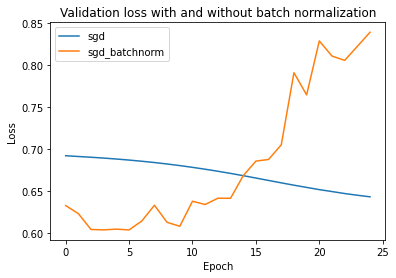

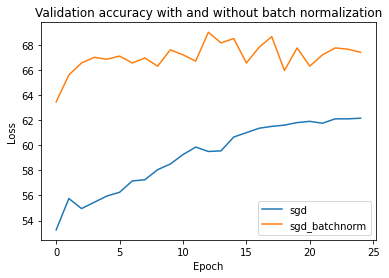

In [53]:
keys = []
for k, v in sorted(batcnorm_training_curves.items()):
    plt.plot(np.arange(len(v[2])), v[2])
    keys.append(k)
plt.title('Validation loss with and without batch normalization')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(keys);

plt.figure()
keys = []
for k, v in sorted(batcnorm_training_curves.items()):
    plt.plot(np.arange(len(v[3])), v[3])
    keys.append(k)
plt.title('Validation accuracy with and without batch normalization')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(keys);

## Tuning
Actually, we already did it. Chooese the best hyperparameters from above experiments giving the best validation error and accuracy. Let's choose 

*   Optimizer: Adam
*   Batch Size 32
*   Model: With Batch Normalization

In [ ]:
model = MLPModelBatchNorm(32*32*3, 128)
model = model.to(device)
learning_rate = 0.001
## STANDARD SGD
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
n_epochs = 25
loss_fn = nn.CrossEntropyLoss()

curves = train(model, train_dataloader, val_dataloader, optimizer, n_epochs, loss_fn)
batcnorm_training_curves['sgd_batchnorm'] = curves

  0%|          | 0/719 [00:00<?, ?it/s]

Epoch 1/25: train_loss: 0.6520, train_accuracy: 61.5130, val_loss: 0.6325, val_accuracy: 63.4500


  0%|          | 0/719 [00:00<?, ?it/s]

Epoch 2/25: train_loss: 0.6232, train_accuracy: 64.7957, val_loss: 0.6229, val_accuracy: 65.6000


  0%|          | 0/719 [00:00<?, ?it/s]

...

Epoch 23/25: train_loss: 0.2955, train_accuracy: 87.2000, val_loss: 0.8057, val_accuracy: 67.7500


  0%|          | 0/719 [00:00<?, ?it/s]

Epoch 24/25: train_loss: 0.2761, train_accuracy: 88.3217, val_loss: 0.8224, val_accuracy: 67.6500


100%|██████████| 719/719 [00:03<00:00, 198.83it/s]


Epoch 25/25: train_loss: 0.2677, train_accuracy: 88.5652, val_loss: 0.8392, val_accuracy: 67.4000


Text(0, 0.5, 'Loss')

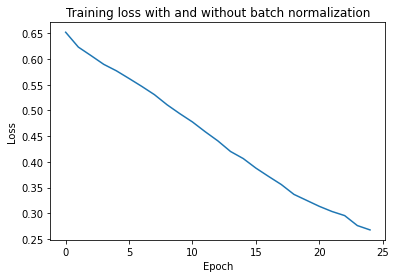

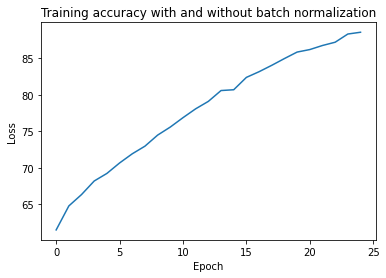

In [ ]:
plt.plot(np.arange(len(curves[0])), curves[0])
plt.title('Training loss with and without batch normalization')
plt.xlabel('Epoch')
plt.ylabel('Loss')

plt.figure()

plt.plot(np.arange(len(curves[1])), curves[1])
plt.title('Training accuracy with and without batch normalization')
plt.xlabel('Epoch')
plt.ylabel('Loss')

Text(0, 0.5, 'Loss')

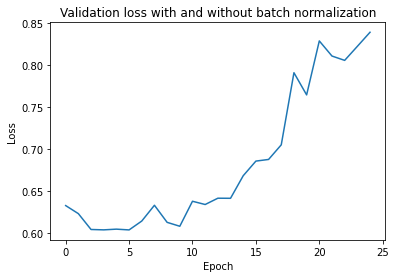

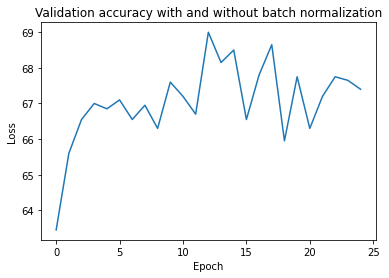

In [ ]:
plt.plot(np.arange(len(curves[2])), curves[2])
plt.title('Validation loss with and without batch normalization')
plt.xlabel('Epoch')
plt.ylabel('Loss')

plt.figure()

plt.plot(np.arange(len(curves[3])), curves[3])
plt.title('Validation accuracy with and without batch normalization')
plt.xlabel('Epoch')
plt.ylabel('Loss')

## Extra Tuning

Another thing could be to play with the learning rate.